# Stablecoin Depeg Monitor

**The question:** How often have USDC, USDT, and DAI lost their $1 peg since 2021, how badly, and which one held up best?

**Who's asking:** a treasury team holding millions in stablecoins that needs to know which one is safest to hold.

**The approach (monitoring):**
1. Define normal: a price close to $1.
2. Define a problem: the daily low below $0.99 or the daily high above $1.01.
3. Scan every day for a break of that rule.
4. Group consecutive flagged days into events and rank them by how bad they were.
5. Explain the worst ones.

## Step 1: Get the prices

Depegs often happen and recover within hours, so the closing price alone can hide them. If USDC fell to $0.88 at 3am and recovered to $0.999 by midnight, the close would show $0.999 but the **low** would show $0.88. So I pull the daily **low** and **high** as well as the close, for every day from January 2021 to September 2026.

In [1]:
import yfinance as yf
import pandas as pd

coins = ["USDC-USD", "USDT-USD", "DAI-USD"]
data = yf.download(coins, start="2021-01-01", end="2026-10-01", progress=False)
data.to_csv("../data/raw_prices.csv")

low, high, close = data["Low"].copy(), data["High"].copy(), data["Close"].copy()
print(f"{len(data)} days, {data.index.min().date()} to {data.index.max().date()}")

2099 days, 2021-01-01 to 2026-09-30


## Step 2: Check the data

In a monitoring project a single bad price looks exactly like a real emergency, so the data has to be checked before anything gets flagged. First: missing days, the most extreme prices, and a summary of each coin.

In [2]:
print("Missing days per coin:")
print(close.isna().sum(), "\n")
print("Lowest daily low:")
print(low.min(), "\n")
print("Highest daily high:")
print(high.max())

Missing days per coin:
Ticker
DAI-USD     0
USDC-USD    0
USDT-USD    0
dtype: int64 

Lowest daily low:
Ticker
DAI-USD     0.897003
USDC-USD    0.877400
USDT-USD    0.948486
dtype: float64 

Highest daily high:
Ticker
DAI-USD     3.668398
USDC-USD    2.349556
USDT-USD    1.033019
dtype: float64


In [3]:
close.describe()

Ticker,DAI-USD,USDC-USD,USDT-USD
count,2099.000000,2099.000000,2099.000000
mean,1.000040,0.999980,1.000056
std,0.001080,0.000746,0.000727
min,0.973869,0.971500,0.995872
25%,0.999737,0.999865,0.999751
50%,0.999925,0.999982,1.000094
75%,1.000142,1.000085,1.000343
max,1.010310,1.010496,1.011530


No days are missing. But a USDC high of about $2.35 and a DAI high of about $3.67 are impossible for a stablecoin. Here are the 5 lowest lows and 5 highest highs for each coin:

In [4]:
for c in coins:
    print(c)
    print("  lowest lows:  ", {str(d.date()): round(v, 4) for d, v in low[c].nsmallest(5).items()})
    print("  highest highs:", {str(d.date()): round(v, 4) for d, v in high[c].nlargest(5).items()})

USDC-USD
  lowest lows:   {'2023-03-11': 0.8774, '2023-03-12': 0.947, '2021-09-09': 0.9874, '2023-03-13': 0.988, '2023-03-21': 0.9964}
  highest highs: {'2021-11-16': 2.3496, '2021-11-17': 1.1735, '2021-04-18': 1.0265, '2022-05-12': 1.0114, '2021-04-04': 1.0111}
USDT-USD
  lowest lows:   {'2022-05-12': 0.9485, '2022-11-10': 0.9815, '2026-05-07': 0.9896, '2026-05-08': 0.9896, '2022-05-11': 0.9935}
  highest highs: {'2021-11-16': 1.033, '2023-03-11': 1.0296, '2021-04-18': 1.028, '2021-11-17': 1.02, '2023-03-12': 1.0163}
DAI-USD
  lowest lows:   {'2023-03-11': 0.897, '2023-03-12': 0.9498, '2021-03-18': 0.9798, '2021-11-10': 0.9846, '2021-12-04': 0.986}
  highest highs: {'2021-11-16': 3.6684, '2021-11-17': 1.5008, '2021-04-18': 1.0266, '2021-03-29': 1.0234, '2021-05-19': 1.0199}


### Cross-checking against a second source

The guide suggests checking suspicious dates on CoinGecko, but CoinGecko's free API only returns the last 365 days, and its daily snapshot doesn't include intraday lows and highs anyway. Instead I download daily low and high prices from two exchanges with free public APIs:

- **Coinbase** for DAI (until Coinbase delisted DAI in May 2026) and USDT (from May 2021)
- **Bitstamp** for USDC and USDT (USDT from June 2021)

**My rule for a bad record:** a price that crosses $0.99 or $1.01 on Yahoo Finance is kept only if the second source *also* crossed that line on the same day. If the second source stayed inside the band, the Yahoo price is a bad record. If there is no second-source data for that day, I keep the price and mark it as unverified.

In [5]:
import requests, time

def coinbase_daily(product, start="2021-01-01", end="2026-10-01"):
    rows, s, end = [], pd.Timestamp(start), pd.Timestamp(end)
    while s < end:
        e = min(s + pd.Timedelta(days=299), end)       # Coinbase returns at most 300 candles per request
        url = f"https://api.exchange.coinbase.com/products/{product}/candles"
        r = requests.get(url, params={"granularity": 86400, "start": s.isoformat(), "end": e.isoformat()}, timeout=30)
        rows += r.json()
        s = e
        time.sleep(0.4)
    df = pd.DataFrame(rows, columns=["time", "low", "high", "open", "close", "volume"]).drop_duplicates("time")
    df.index = pd.to_datetime(df["time"], unit="s")
    return df.sort_index()[["low", "high"]]

def bitstamp_daily(pair, start="2021-01-01", end="2026-10-01"):
    rows, ts = [], int(pd.Timestamp(start).timestamp())
    while ts < pd.Timestamp(end).timestamp():
        url = f"https://www.bitstamp.net/api/v2/ohlc/{pair}/"
        batch = requests.get(url, params={"step": 86400, "limit": 1000, "start": ts}, timeout=30).json()["data"]["ohlc"]
        if not batch:
            break
        rows += batch
        ts = int(batch[-1]["timestamp"]) + 86400
        time.sleep(0.4)
    df = pd.DataFrame(rows)
    df.index = pd.to_datetime(df["timestamp"].astype(int), unit="s")
    return df[["low", "high"]].astype(float)

cb_dai, cb_usdt = coinbase_daily("DAI-USD"), coinbase_daily("USDT-USD")
bs_usdc, bs_usdt = bitstamp_daily("usdcusd"), bitstamp_daily("usdtusd")

# For USDT there are two exchanges: take the lowest low and highest high across them
check_low = pd.DataFrame({
    "USDC-USD": bs_usdc["low"],
    "USDT-USD": pd.concat([cb_usdt["low"], bs_usdt["low"]], axis=1).min(axis=1),
    "DAI-USD": cb_dai["low"],
}).reindex(low.index)
check_high = pd.DataFrame({
    "USDC-USD": bs_usdc["high"],
    "USDT-USD": pd.concat([cb_usdt["high"], bs_usdt["high"]], axis=1).max(axis=1),
    "DAI-USD": cb_dai["high"],
}).reindex(high.index)

pd.concat({"low": check_low, "high": check_high}, axis=1).to_csv("../data/crosscheck_prices.csv")
print("Days with second-source data:")
print(check_low.notna().sum())

Days with second-source data:
USDC-USD    2099
USDT-USD    1976
DAI-USD     1950
dtype: int64


Now apply the rule. A bad low or high gets replaced with the second source's price for that day, so the day stays in the data but the bad spike doesn't.

In [6]:
bad_low = (low < 0.99) & check_low.notna() & (check_low >= 0.99)
bad_high = (high > 1.01) & check_high.notna() & (check_high <= 1.01)
unverified = ((low < 0.99) | (high > 1.01)) & check_low.isna()

def as_table(mask, yahoo, second, side):
    t = pd.DataFrame({"yahoo": yahoo.where(mask).stack().dropna(),
                      "second_source": second.where(mask).stack().dropna()})
    return t.assign(side=side).round(4)

removed = pd.concat([as_table(bad_low, low, check_low, "low"),
                     as_table(bad_high, high, check_high, "high")]).sort_index()
removed.index.names = ["date", "coin"]
print(f"Removed {len(removed)} bad prices on {removed.index.get_level_values('date').nunique()} days")
print(removed.groupby("coin").size(), "\n")
print("Flagged days with no second source (kept, unverified):")
print(unverified.stack()[lambda s: s])

low = low.mask(bad_low, check_low)
high = high.mask(bad_high, check_high)
removed

Removed 34 bad prices on 25 days
coin
DAI-USD     23
USDC-USD     6
USDT-USD     5
dtype: int64 

Flagged days with no second source (kept, unverified):
Date        Ticker  
2021-04-04  USDT-USD    True
2021-04-17  USDT-USD    True
2021-04-18  USDT-USD    True
dtype: bool


yahoo  second_source  side
date       coin                                 
2021-03-18 DAI-USD   0.9798         1.0006   low
2021-03-29 DAI-USD   1.0234         1.0014  high
2021-04-02 DAI-USD   1.0103         1.0011  high
2021-04-03 DAI-USD   1.0111         1.0013  high
2021-04-04 DAI-USD   1.0129         1.0012  high
           USDC-USD  1.0111         1.0041  high
2021-04-17 DAI-USD   1.0113         1.0013  high
2021-04-18 DAI-USD   1.0266         1.0076  high
2021-05-19 DAI-USD   0.9896         0.9970   low
2021-06-15 DAI-USD   1.0114         1.0018  high
           USDC-USD  1.0102         1.0099  high
           USDT-USD  1.0104         1.0026  high
2021-09-09 USDC-USD  0.9874         0.9999   low
2021-11-10 DAI-USD   0.9846         0.9990   low
           DAI-USD   1.0198         1.0005  high
2021-11-11 DAI-USD   0.9881         0.9994   low
2021-11-12 DAI-USD   1.0124         1.0010  high
2021-11-16 DAI-USD   3.6684         1.0008  high
           USDC-USD  2.3496         1.0010  high
           USDT-USD  1.0330         1.0065  high
2021-11-17 DAI-USD   1.5008         1.0004  high
           USDC-USD  1.1735         1.0015  high
           USDT-USD  1.0200         1.0037  high
2021-12-04 DAI-USD   0.9860         0.9995   low
2021-12-06 DAI-USD   1.0111         1.0006  high
2021-12-07 DAI-USD   1.0105         1.0004  high
2021-12-13 DAI-USD   0.9896         0.9994   low
2021-12-15 DAI-USD   1.0103         1.0003  high
2021-12-17 DAI-USD   0.9899         0.9992   low
2022-05-12 DAI-USD   1.0138         1.0010  high
           USDC-USD  1.0114         1.0011  high
2025-01-01 DAI-USD   1.0117         1.0100  high
2026-05-07 USDT-USD  0.9896         0.9980   low
2026-05-08 USDT-USD  0.9896         0.9977   low

### Data checks

- **Missing days:** none. All 2,099 days from Jan 1, 2021 to Sep 30, 2026 are present for all three coins.
- **Impossible prices:** on Nov 16 and 17, 2021 Yahoo shows highs of $2.35 for USDC, $3.67 and $1.50 for DAI, and $1.03 for USDT, on the same days, with no news. Both exchanges show all three coins within a fraction of a cent of $1. These are bad records and were removed.
- **Bad lows that would have looked like depegs:** USDT at $0.9896 on May 7 and 8, 2026 (Coinbase low $0.998, Bitstamp $0.9997, and CoinGecko's hourly prices never went below $0.9997), USDC at $0.9874 on Sep 9, 2021, and seven DAI lows between $0.980 and $0.990 in 2021 that Coinbase doesn't show. All removed.
- **In total I removed 34 prices on 25 days** (USDC 6, USDT 5, DAI 23). Most are small highs just above $1.01 in 2021 that the exchanges don't confirm.
- **Kept:** every price from the events that matter. USDC and DAI in March 2023, USDT in May 2022 (Terra collapse) and November 2022 (FTX collapse) are all confirmed by the second source, which in each case shows an equal or deeper move.
- **Unverified:** three USDT highs in April 2021 (the 4th, 17th, and 18th) happened before either exchange listed USDT. I kept them. USDC and DAI also spiked above $1.01 on April 18, 2021 on the exchanges, which makes them plausible.
- **Closing prices:** a few 2021 DAI closes sit more than half a cent from $1 where Coinbase shows a tighter range (for example $0.9878 on Nov 10, 2021). Closes only feed the day-to-day stability measures, not the depeg flags, so I left them in. If anything, this makes DAI look slightly less stable than it was.

## Step 3: Explore what normal looks like

You can't set a smart threshold without knowing how much these coins usually wiggle.

**Prediction before looking:** I expect USDT to have the most small wobbles and USDC to have the single worst event.

I measure how far each day's close is from $1, in cents. I look at the **median** rather than the average because a few crisis days (like USDC at 87 cents) pull the average up, while the median shows a typical day.

In [7]:
import matplotlib.pyplot as plt

distance = (close - 1).abs()     # how far from $1 each day
print("Distance from $1, in cents:")
(distance * 100).describe(percentiles=[0.5, 0.9, 0.99]).round(3)

Distance from $1, in cents:


Ticker,DAI-USD,USDC-USD,USDT-USD
count,2099.000,2099.000,2099.000
mean,0.046,0.020,0.046
std,0.098,0.072,0.056
min,0.000,0.000,0.000
50%,0.022,0.011,0.031
90%,0.105,0.036,0.104
99%,0.437,0.131,0.218
max,2.613,2.850,1.153


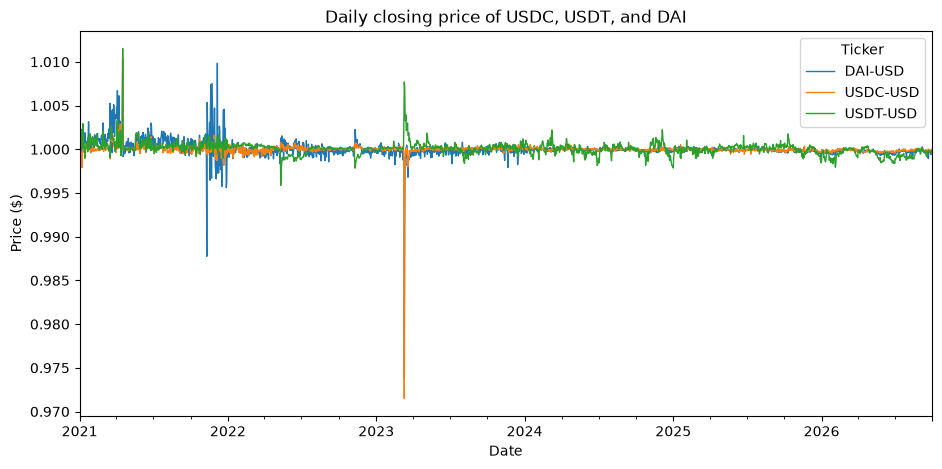

In [8]:
ax = close.plot(figsize=(11, 5), title="Daily closing price of USDC, USDT, and DAI", lw=1)
ax.set_ylabel("Price ($)")
plt.show()

**A normal day:** on a typical day USDC closes about 0.01 cents from $1, DAI about 0.02 cents, and USDT about 0.03 cents. Even the 99th percentile day is under half a cent for every coin (USDC 0.13, USDT 0.22, DAI 0.44 cents). A $0.99 / $1.01 line is a full cent away, more than twice the 99th percentile of the noisiest coin. It sits far outside normal noise and only catches real problems.

The closing price chart is flat except for March 2023. The closes hide most of the story, which is why the next steps use the daily low and high.

My prediction was half right: USDT does have the largest everyday wobble (highest median distance), and USDC does have the worst single event.

## Step 4: Flag bad days and group them into events

Two choices shape every result:

- **The threshold:** a day is flagged if the daily low is below $0.99 **or** the daily high is above $1.01. Step 3 showed normal days stay well within half a cent, so this catches real problems without false alarms. Trading above $1.01 counts too: it means the market doesn't trust the price to hold, and people are paying a premium to get in (usually while running from something else).
- **One event:** consecutive flagged days count as one event. If USDC is flagged three days in a row, that's one three-day event, not three events.

Events are ranked by their **worst gap**: the furthest the price got from $1 in either direction.

In [9]:
flag = (low < 0.99) | (high > 1.01)
print("Flagged days per coin:")
print(flag.sum())

def find_events(coin):
    f = flag[coin]
    groups = (f != f.shift()).cumsum()   # new group number each time the flag switches on or off
    rows = []
    for _, days in low[coin][f].groupby(groups[f]):
        lo, hi = days.min(), high[coin][days.index].max()
        rows.append({"coin": coin.replace("-USD", ""),
                     "start": days.index[0].date(),
                     "end": days.index[-1].date(),
                     "days": len(days),
                     "direction": "below $1" if 1 - lo > hi - 1 else "above $1",
                     "lowest_price": round(lo, 4),
                     "highest_price": round(hi, 4),
                     "worst_gap_cents": round(max(1 - lo, hi - 1) * 100, 2)})
    return pd.DataFrame(rows)

events = (pd.concat([find_events(c) for c in coins])
          .sort_values("worst_gap_cents", ascending=False)
          .reset_index(drop=True))
events.to_csv("../data/depeg_events.csv", index=False)
events

Flagged days per coin:
Ticker
DAI-USD     8
USDC-USD    5
USDT-USD    8
dtype: int64


,coin,start,end,days,direction,lowest_price,highest_price,worst_gap_cents
0,USDC,2023-03-11,2023-03-13,3,below $1,0.8774,1.0003,12.26
1,DAI,2023-03-11,2023-03-13,3,below $1,0.8970,1.0011,10.30
2,USDT,2022-05-12,2022-05-12,1,below $1,0.9485,0.9977,5.15
3,USDT,2023-03-11,2023-03-13,3,above $1,1.0013,1.0296,2.96
4,USDT,2021-04-17,2021-04-18,2,above $1,0.9995,1.0280,2.80
5,USDC,2021-04-17,2021-04-18,2,above $1,0.9988,1.0265,2.65
6,DAI,2021-05-19,2021-05-19,1,above $1,0.9970,1.0199,1.99
7,DAI,2021-02-22,2021-02-23,2,above $1,0.9998,1.0193,1.93
8,USDT,2022-11-10,2022-11-10,1,below $1,0.9815,0.9990,1.85
9,DAI,2021-01-11,2021-01-11,1,above $1,0.9985,1.0131,1.31


How the grouping works: `f.shift()` is yesterday's flag. Each time today's flag differs from yesterday's, a new stretch starts, and `cumsum()` gives it a new number. For five days `False, True, True, False, True` the group numbers are `1, 2, 2, 3, 4`, so the two True stretches become groups 2 and 4: one 2-day event and one 1-day event.

**12 events in total, but only 4 below $1.** The two worst by far are USDC and DAI in March 2023. USDT's only two drops below $0.99 were in 2022, during the Terra and FTX collapses. The other 8 events are the price trading *above* $1.01, mostly during the 2021 bull market and selloffs, when demand for stablecoins spiked faster than supply.

## Step 5: Compare the three coins

"Safest" can mean different things, so I compare on several measures:

- **Day-to-day stability:** how often the close stays within half a cent of $1, and how far from $1 it typically is.
- **Frequency:** how many depeg events, and how many were drops below $1 (the kind that loses a treasury money).
- **Severity:** the worst price ever reached.

In [10]:
event_coin = events["coin"] + "-USD"
comparison = pd.DataFrame({
    "Days within $0.995 to $1.005 (%)": ((close - 1).abs() <= 0.005).mean() * 100,
    "Median distance from $1 (cents)": distance.median() * 100,
    "Average distance from $1 (cents)": distance.mean() * 100,
    "Depeg events": event_coin.value_counts().reindex(coins, fill_value=0),
    "Events below $0.99": event_coin[events["lowest_price"] < 0.99].value_counts().reindex(coins, fill_value=0),
    "Worst low ($)": low.min(),
    "Highest high ($)": high.max(),
}).round(4)
comparison.index = [c.replace("-USD", "") for c in comparison.index]
comparison

,Days within $0.995 to $1.005 (%),Median distance from $1 (cents),Average distance from $1 (cents),Depeg events,Events below $0.99,Worst low ($),Highest high ($)
DAI,99.4283,0.0224,0.0462,5,1,0.8970,1.0199
USDC,99.8571,0.0112,0.0195,2,1,0.8774,1.0265
USDT,99.8571,0.0307,0.0464,5,2,0.9485,1.0296


### Findings

**No single coin wins on every measure, and that's the honest answer.**

- **USDC was the most stable day to day**, staying within half a cent of $1 on 99.86% of days, with a typical distance of about 0.01 cents (USDT ties on the half-cent measure, but its typical distance is almost three times bigger). Yet **USDC also had the single worst event: a fall to $0.877 on March 11, 2023**, when Silicon Valley Bank collapsed. A treasury holding $10 million in USDC would have been down about $1.2 million at that low.
- **USDT never fell below $0.948**, its worst moment being the Terra collapse in May 2022, and it had the mildest worst case of the three. It had 5 events, but only 2 were drops below $1 (Terra in May 2022 and FTX in November 2022).
- **DAI was the least stable day to day.** It had the lowest share of days within half a cent (99.43%) and the widest swings on its worst 1% of days (0.44 cents, twice USDT's), tied USDT with 5 events, and fell to $0.897 in March 2023 because much of its backing was USDC.

**For the treasury team:** if the biggest fear is one sharp loss, USDT had the shallowest worst case in this period. If the concern is everyday reliability, USDC was the steadiest. DAI was neither, and it carries USDC's risk on top of its own.